In [1]:
import pandas as pd
url = "https://raw.githubusercontent.com/OpenNeuroDatasets/ds003823/main/phenotype/Whoop_Summary.tsv"
df = pd.read_csv(url, sep="\t")
display(df)

,participant_id,age_group,group,date,day.of.week,rhr,hrv,sleep.onset,wake.onset,hours.in.bed,hours.of.sleep,sleep.disturbances,latency.min,cycles,rem.sleep.hours,deep.sleep.hours,light.sleep.hours,awake.hours,missing.data.hours,session
0,sub-5006,Young,Increase,5/5/2018,Saturday,57.0,131.0,1:30:28,9:30:27,8.00,7.45,7.0,3.98,8.0,2.18,0.49,4.78,0.55,0.0,Pre
1,sub-5006,Young,Increase,5/6/2018,Sunday,63.0,51.0,2:03:05,9:25:04,7.37,6.52,8.0,4.98,7.0,2.32,0.52,3.67,0.85,0.0,Pre
2,sub-5006,Young,Increase,5/7/2018,Monday,56.0,92.0,3:53:19,9:50:47,5.96,5.02,7.0,3.48,5.0,1.36,0.68,2.97,0.94,0.0,Pre
3,sub-5006,Young,Increase,5/8/2018,Tuesday,63.0,68.0,1:56:27,7:19:26,5.38,4.74,6.0,2.98,5.0,1.14,0.85,2.75,0.64,0.0,Pre
4,sub-5006,Young,Increase,5/9/2018,Wednesday,60.0,65.0,2:52:55,9:59:54,7.12,6.08,5.0,2.48,6.0,0.97,0.41,4.71,1.03,0.0,Pre
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
5630,sub-8034,Old,Decrease,3/13/2020,Friday,58.0,44.0,0:24:58,7:45:29,7.34,5.70,7.0,3.02,3.0,0.91,1.86,2.93,1.64,0.0,NaN
5631,sub-8034,Old,Decrease,3/14/2020,Saturday,61.0,56.0,2:14:22,8:32:29,6.30,5.36,6.0,1.62,4.0,1.52,1.16,2.67,0.94,0.0,NaN
5632,sub-8035,Old,Decrease,2/11/2020,Tuesday,50.0,67.0,0:29:00,7:37:58,7.15,6.92,6.0,1.48,5.0,1.31,1.02,4.59,0.22,0.0,NaN
5633,sub-8035,Old,Decrease,2/12/2020,Wednesday,48.0,63.0,23:58:25,7:32:23,7.57,6.69,5.0,1.98,3.0,0.86,1.55,4.28,0.87,0.0,NaN


In [2]:
features = [
    "rhr",
    "hrv",
    "hours.of.sleep",
    "sleep.disturbances",
    "latency.min",
]
df[features]

,rhr,hrv,hours.of.sleep,sleep.disturbances,latency.min
0,57.0,131.0,7.45,7.0,3.98
1,63.0,51.0,6.52,8.0,4.98
2,56.0,92.0,5.02,7.0,3.48
3,63.0,68.0,4.74,6.0,2.98
4,60.0,65.0,6.08,5.0,2.48
...,...,...,...,...,...
5630,58.0,44.0,5.70,7.0,3.02
5631,61.0,56.0,5.36,6.0,1.62
5632,50.0,67.0,6.92,6.0,1.48
5633,48.0,63.0,6.69,5.0,1.98


In [3]:
import numpy as np
# X should be your numeric data matrix: shape = (n_samples, n_features)
X = df[["rhr", "hrv", "hours.of.sleep", "sleep.disturbances", "latency.min"]].dropna().to_numpy()
X

array([[ 57.  , 131.  ,   7.45,   7.  ,   3.98],
       [ 63.  ,  51.  ,   6.52,   8.  ,   4.98],
       [ 56.  ,  92.  ,   5.02,   7.  ,   3.48],
       ...,
       [ 50.  ,  67.  ,   6.92,   6.  ,   1.48],
       [ 48.  ,  63.  ,   6.69,   5.  ,   1.98],
       [ 50.  ,  43.  ,   5.97,   5.  ,   2.87]])

In [4]:
K = 3
max_iter = 100
tol = 1e-4
np.random.seed(42)
n, d = X.shape

In [5]:
# Scale data
X = (X - X.mean(axis=0)) / X.std(axis=0)
X

array([[-0.42656543,  1.59095855,  0.86997513,  0.11727906,  0.20914439],
       [ 0.29665423, -0.47656609,  0.36438833,  0.35890581,  0.39203347],
       [-0.54710204,  0.58304029, -0.45107426,  0.11727906,  0.11769985],
       ...,
       [-1.27032169, -0.06306116,  0.58184502, -0.1243477 , -0.2480783 ],
       [-1.51139491, -0.16643739,  0.45680742, -0.36597445, -0.15663376],
       [-1.27032169, -0.68331855,  0.06538538, -0.36597445,  0.00613752]])

In [6]:
# 1. Initialize μ, Σ, π
random_rows = np.random.choice(n, K, replace=False)
mu = X[random_rows]
mu

array([[-1.14978508,  2.13368377, -0.47281993,  0.11727906,  0.483478  ],
       [-0.42656543,  0.81563681, -0.67396737,  0.35890581, -0.51875413],
       [-1.87300474,  1.4358942 , -0.21730832, -0.1243477 , -0.06518922]])

In [7]:
Sigma = np.array([np.eye(d) for _ in range(K)])
Sigma

array([[[1., 0., 0., 0., 0.],
        [0., 1., 0., 0., 0.],
        [0., 0., 1., 0., 0.],
        [0., 0., 0., 1., 0.],
        [0., 0., 0., 0., 1.]],

       [[1., 0., 0., 0., 0.],
        [0., 1., 0., 0., 0.],
        [0., 0., 1., 0., 0.],
        [0., 0., 0., 1., 0.],
        [0., 0., 0., 0., 1.]],

       [[1., 0., 0., 0., 0.],
        [0., 1., 0., 0., 0.],
        [0., 0., 1., 0., 0.],
        [0., 0., 0., 1., 0.],
        [0., 0., 0., 0., 1.]]])

In [8]:
pi = np.ones(K) / K
pi

array([0.33333333, 0.33333333, 0.33333333])

In [9]:
def gaussian_pdf(x, mu, Sigma):
    d = len(mu)

    Sigma = Sigma + 1e-6 * np.eye(d)

    det = np.linalg.det(Sigma)
    inv = np.linalg.inv(Sigma)

    diff = x - mu

    return (
        1 / np.sqrt((2 * np.pi) ** d * det)
        * np.exp(-0.5 * diff.T @ inv @ diff)
    )


In [10]:
for iteration in range(max_iter):

    # 2. E-step: compute responsibilities r_ik
    r = np.zeros((n, K))

    for i in range(n):
        for k in range(K):
            r[i, k] = pi[k] * gaussian_pdf(X[i], mu[k], Sigma[k])

        r[i, :] = r[i, :] / r[i, :].sum()

    # 3. M-step: update parameters
    N_k = r.sum(axis=0)

    for k in range(K):
        # update μ_k
        mu[k] = np.sum(r[:, k].reshape(-1, 1) * X, axis=0) / N_k[k]

        # update Σ_k
        Sigma[k] = np.zeros((d, d))

        for i in range(n):
            diff = (X[i] - mu[k]).reshape(-1, 1)
            Sigma[k] += r[i, k] * (diff @ diff.T)

        Sigma[k] = Sigma[k] / N_k[k]

        # update π_k
        pi[k] = N_k[k] / n

    # 4. Log-likelihood
    log_likelihood = 0

    for i in range(n):
        total = 0
        for k in range(K):
            total += pi[k] * gaussian_pdf(X[i], mu[k], Sigma[k])

        log_likelihood += np.log(total)

    print(f"Iteration {iteration + 1}, log-likelihood: {log_likelihood:.4f}")

    if iteration > 0 and abs(log_likelihood - old_log_likelihood) < tol:
        print("Converged")
        break

    old_log_likelihood = log_likelihood




Iteration 1, log-likelihood: -34174.8931
Iteration 2, log-likelihood: -32902.2543
Iteration 3, log-likelihood: -32652.6480
Iteration 4, log-likelihood: -32586.8580
Iteration 5, log-likelihood: -32556.2082
Iteration 6, log-likelihood: -32536.5155
Iteration 7, log-likelihood: -32522.0708
Iteration 8, log-likelihood: -32510.7256
Iteration 9, log-likelihood: -32501.3261
Iteration 10, log-likelihood: -32493.1295
Iteration 11, log-likelihood: -32485.6326
Iteration 12, log-likelihood: -32478.4874
Iteration 13, log-likelihood: -32471.4333
Iteration 14, log-likelihood: -32464.2506
Iteration 15, log-likelihood: -32456.7610
Iteration 16, log-likelihood: -32448.9149
Iteration 17, log-likelihood: -32441.0554
Iteration 18, log-likelihood: -32434.0065
Iteration 19, log-likelihood: -32428.1529
Iteration 20, log-likelihood: -32423.2156
Iteration 21, log-likelihood: -32418.9210
Iteration 22, log-likelihood: -32415.1073
Iteration 23, log-likelihood: -32411.6283
Iteration 24, log-likelihood: -32408.3339
I

In [11]:
# Final cluster assignment
clusters = np.argmax(r, axis=1)

print("Means:")
print(mu)

print("\nCovariances:")
print(Sigma)

print("\nMixing weights:")
print(pi)

print("\nCluster assignments:")
print(clusters)

print("\nResponsibilities:")
print(r)

Means:
[[-0.10860919  0.32560968 -0.18343036 -0.25686019  2.18312347]
 [-0.12897612 -0.19454546  0.2863494   0.43691402 -0.24410743]
 [ 0.17270578  0.1801581  -0.31373822 -0.48248306 -0.06526816]]

Covariances:
[[[ 1.35985451e+00 -6.50902192e-01 -1.51943538e-01 -6.02962060e-02
    1.62085636e-01]
  [-6.50902192e-01  1.15373687e+00  6.92107907e-03  7.96703422e-02
   -7.47490504e-03]
  [-1.51943538e-01  6.92107907e-03  7.64011156e-01  3.01210926e-01
   -4.87802699e-01]
  [-6.02962060e-02  7.96703422e-02  3.01210926e-01  5.57973975e-01
   -2.16634402e-01]
  [ 1.62085636e-01 -7.47490504e-03 -4.87802699e-01 -2.16634402e-01
    8.24179631e+00]]

 [[ 6.51804398e-01 -1.29372770e-01 -4.70352937e-02  1.39561825e-01
   -1.91473373e-02]
  [-1.29372770e-01  7.18339447e-01  1.04855730e-01  2.94269587e-01
   -7.41701849e-02]
  [-4.70352937e-02  1.04855730e-01  6.25663161e-01  2.86217705e-01
   -1.74799783e-02]
  [ 1.39561825e-01  2.94269587e-01  2.86217705e-01  1.15264011e+00
   -4.93867886e-02]
  [-

In [12]:
import pandas as pd
from sklearn.mixture import GaussianMixture
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline

# df = your sleep dataframe

features = [
    "rhr",
    "hrv",
    "hours.of.sleep",
    "sleep.disturbances",
    "latency.min",
    "cycles",
    "rem.sleep.hours",
    "deep.sleep.hours",
    "light.sleep.hours",
    "awake.hours"
]

features = [
    "rhr",
    "hrv",
    "hours.of.sleep",
    "sleep.disturbances",
    "latency.min",
]


X = df[features]

# Fill missing values and standardize variables
prep = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

X_scaled = prep.fit_transform(X)

# Try different numbers of hidden profiles
results = []

for k in range(1,10):
    gmm = GaussianMixture(
        n_components=k,
        covariance_type="full",
        random_state=42,
        n_init=20
    )
    gmm.fit(X_scaled)

    results.append({
        "k": k,
        "bic": gmm.bic(X_scaled),
        "aic": gmm.aic(X_scaled)
    })

results_df = pd.DataFrame(results)
display(results_df)



,k,bic,aic
0,1,77636.389946,77503.654898
1,2,66736.093291,66463.986441
2,3,64796.319355,64384.840704
3,4,61599.556002,61048.705550
4,5,51595.053302,50904.831050
5,6,51441.981819,50612.387766
6,7,46097.658150,45128.692296
7,8,46059.224868,44950.887213
8,9,45975.596012,44727.886555


In [13]:
# Choose best number of profiles using lowest BIC
best_k = results_df.loc[results_df["bic"].idxmin(), "k"]
best_k = 3
print("Best number of hidden profiles:", best_k)

# Fit final EM model
final_gmm = GaussianMixture(
    n_components=int(best_k),
    covariance_type="full",
    random_state=42,
    n_init=50
)

final_gmm.fit(X_scaled)

# Assign each row/night to a hidden profile
df["sleep_profile"] = final_gmm.predict(X_scaled)

# Add probability of belonging to each profile
profile_probs = final_gmm.predict_proba(X_scaled)

prob_df = pd.DataFrame(
    profile_probs,
    columns=[f"profile_{i}_prob" for i in range(int(best_k))]
)

df = pd.concat([df.reset_index(drop=True), prob_df], axis=1)

# Summarize each hidden profile
profile_summary = df.groupby("sleep_profile")[features].mean()
display(profile_summary)

df["sleep_profile"].value_counts().sort_index()

Best number of hidden profiles: 3


,rhr,hrv,hours.of.sleep,sleep.disturbances,latency.min
sleep_profile,,,,,
0,62.033409,39.696279,5.756877,5.301287,2.028164
1,59.123438,98.032422,5.994465,7.944141,1.729254
2,59.779126,81.936893,5.486787,5.268116,14.949952


,count
sleep_profile,
0,2661
1,2560
2,414


In [14]:
final_gmm.means_

array([[ 0.19035798, -0.74599155, -0.0479262 , -0.29347809, -0.14703256],
       [-0.15780135,  0.62350181,  0.07958115,  0.32819542, -0.20421757],
       [-0.10130156,  0.36981685, -0.18698713, -0.2965694 ,  1.81704877]])

In [15]:
final_gmm.covariances_

array([[[ 9.72480362e-01, -1.44165008e-01, -1.02717535e-01,
         -1.09700690e-01, -3.52401428e-03],
        [-1.44165008e-01,  1.45172820e-01,  3.28590689e-02,
          4.09716887e-03, -2.32877413e-02],
        [-1.02717535e-01,  3.28590689e-02,  9.55756279e-01,
          2.86163474e-01,  6.52000583e-03],
        [-1.09700690e-01,  4.09716887e-03,  2.86163474e-01,
          5.00639753e-01, -8.19034196e-03],
        [-3.52401428e-03, -2.32877413e-02,  6.52000583e-03,
         -8.19034196e-03,  5.55044961e-02]],

       [[ 8.94699384e-01, -2.94656119e-01, -7.77225201e-02,
          1.59266466e-01, -1.60330787e-03],
        [-2.94656119e-01,  8.42442217e-01, -8.12290965e-02,
         -1.70424630e-01, -2.13953556e-02],
        [-7.77225201e-02, -8.12290965e-02,  1.06251034e+00,
          6.19058179e-01, -3.63182394e-02],
        [ 1.59266466e-01, -1.70424630e-01,  6.19058179e-01,
          1.35685292e+00, -7.47837391e-02],
        [-1.60330787e-03, -2.13953556e-02, -3.63182394e-02,
  

In [16]:
final_gmm.weights_

array([0.43886353, 0.47251819, 0.08861828])

In [17]:
import numpy as np
from scipy.stats import multivariate_normal

In [18]:
X = X_scaled

weights = final_gmm.weights_        # pi_j
means = final_gmm.means_            # mu_j
covariances = final_gmm.covariances_ # Sigma_j

n = X.shape[0]
k = final_gmm.n_components

In [19]:
component_densities = np.column_stack([
    multivariate_normal.pdf(
        X,
        mean=means[j],
        cov=covariances[j],
        allow_singular=True
    )
    for j in range(k)
])
component_densities

array([[3.03751957e-13, 3.91998368e-03, 1.41300534e-03],
       [2.33256825e-03, 2.35745741e-03, 2.56491307e-03],
       [1.19294335e-05, 1.83814675e-02, 3.30522350e-03],
       ...,
       [2.61393424e-02, 8.50751039e-03, 1.43566373e-03],
       [2.56620057e-02, 4.64141929e-03, 8.85071166e-04],
       [5.22596837e-02, 2.62976747e-03, 6.49644325e-04]])

In [20]:
weighted_densities = component_densities * weights
weighted_densities

array([[1.33305655e-13, 1.85226359e-03, 1.25218109e-04],
       [1.02367913e-03, 1.11394150e-03, 2.27298195e-04],
       [5.23539326e-06, 8.68557770e-03, 2.92903236e-04],
       ...,
       [1.14716040e-02, 4.01995339e-03, 1.27226057e-04],
       [1.12621183e-02, 2.19315503e-03, 7.84334882e-05],
       [2.29348691e-02, 1.24261296e-03, 5.75703655e-05]])

In [21]:
likelihoods = component_densities@weights
likelihoods

array([0.00197748, 0.00236492, 0.00898372, ..., 0.01561878, 0.01353371,
       0.02423505])

In [22]:
log_likelihoods = np.log(likelihoods)
log_likelihoods

array([-6.22593111, -6.04701158, -4.71234164, ..., -4.15928102,
       -4.3025719 , -3.71995524])

In [23]:
final_gmm.score_samples(X_scaled)

array([-6.22593111, -6.04701158, -4.71234164, ..., -4.15928102,
       -4.3025719 , -3.71995524])

In [24]:
final_gmm.score(X_scaled)

np.float64(-5.701898745020155)

In [25]:
np.mean(log_likelihoods)

np.float64(-5.701898745020155)

In [26]:
probas_manual = weighted_densities / likelihoods[:, None]
probas_manual

array([[6.74118278e-11, 9.36677993e-01, 6.33220066e-02],
       [4.32860155e-01, 4.71027373e-01, 9.61124722e-02],
       [5.82764756e-04, 9.66813441e-01, 3.26037939e-02],
       ...,
       [7.34474874e-01, 2.57379418e-01, 8.14570848e-03],
       [8.32153264e-01, 1.62051318e-01, 5.79541798e-03],
       [9.46351124e-01, 5.12733762e-02, 2.37549993e-03]])

In [27]:
final_gmm.predict_proba(X_scaled)

array([[6.74118278e-11, 9.36677993e-01, 6.33220066e-02],
       [4.32860155e-01, 4.71027373e-01, 9.61124722e-02],
       [5.82764756e-04, 9.66813441e-01, 3.26037939e-02],
       ...,
       [7.34474874e-01, 2.57379418e-01, 8.14570848e-03],
       [8.32153264e-01, 1.62051318e-01, 5.79541798e-03],
       [9.46351124e-01, 5.12733762e-02, 2.37549993e-03]])

In [28]:
p = final_gmm._n_parameters()
p

62

In [29]:
p = k-1 + k*d + k*((d**2 - d)/2 +d) # weights + means + covariances
p

62.0

In [30]:
aic = 2 * p - 2 * log_likelihoods.sum()
display(aic)
final_gmm.aic(X_scaled)

np.float64(64384.39885637715)

np.float64(64384.39885637714)

In [31]:
bic = p * np.log(n) - 2 * log_likelihoods.sum()
display(bic)
final_gmm.bic(X_scaled)

np.float64(64795.87750681853)

np.float64(64795.87750681852)

In [32]:
import pandas as pd

scaled_df = pd.DataFrame(X_scaled, columns=features)

scaled_df["sleep_profile"] = df["sleep_profile"]

profile_z = scaled_df.groupby("sleep_profile").mean()

display(profile_z.round(2))

,rhr,hrv,hours.of.sleep,sleep.disturbances,latency.min
sleep_profile,,,,,
0,0.18,-0.76,-0.05,-0.29,-0.15
1,-0.17,0.74,0.08,0.35,-0.20
2,-0.09,0.32,-0.19,-0.30,2.21


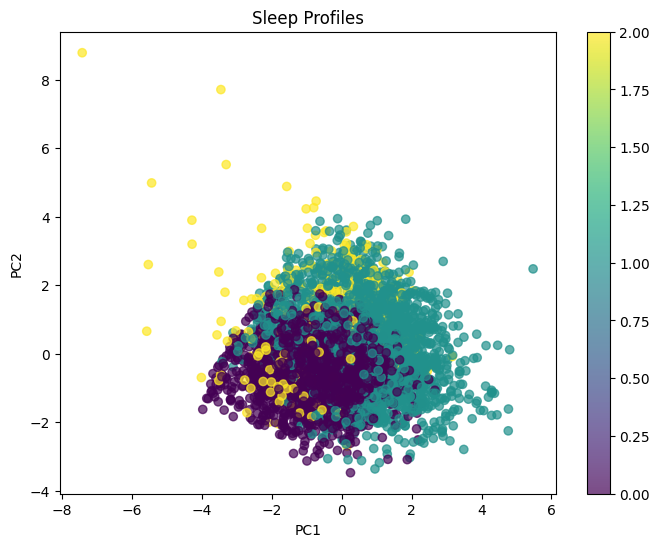

In [33]:
from sklearn.decomposition import PCA
import matplotlib.pyplot as plt

pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_scaled)

plt.figure(figsize=(8,6))

scatter = plt.scatter(
    X_pca[:,0],
    X_pca[:,1],
    c=df["sleep_profile"],
    alpha=0.7
)

plt.xlabel("PC1")
plt.ylabel("PC2")
plt.title("Sleep Profiles")
plt.colorbar(scatter)
plt.show()

In [34]:
import numpy as np
import pandas as pd

# 1. Create standardized feature table
scaled_df = pd.DataFrame(X_scaled, columns=features)
scaled_df["sleep_profile"] = df["sleep_profile"].values

# 2. Get mean z-scores per profile
profile_z = scaled_df.groupby("sleep_profile")[features].mean()

# 3. Define scoring rules
scores = pd.DataFrame(index=profile_z.index)

scores["high_recovery"] = (
    -profile_z["rhr"]
    + profile_z["hrv"]
    + profile_z["hours.of.sleep"]
    - profile_z["sleep.disturbances"]
    - profile_z["latency.min"]
)

scores["fragmented_sleep"] = (
    profile_z["sleep.disturbances"]
    + profile_z.get("awake.hours", 0)
    - profile_z["hours.of.sleep"]
)

scores["sleep_debt"] = (
    -profile_z["hours.of.sleep"]
    + profile_z["rhr"]
    - profile_z["hrv"]
)

scores["efficient_short_sleep"] = (
    -profile_z["hours.of.sleep"]
    + profile_z["hrv"]
    - profile_z["rhr"]
    - profile_z["sleep.disturbances"]
)

scores["autonomic_stress"] = (
    profile_z["rhr"]
    - profile_z["hrv"]
    + profile_z["latency.min"]
)

# 4. Assign each profile the label it scores highest on
raw_labels = scores.idxmax(axis=1)

# 5. Make labels unique if two profiles get same name
label_counts = {}
profile_names = {}

for profile, label in raw_labels.items():
    label_counts[label] = label_counts.get(label, 0) + 1

    if label_counts[label] == 1:
        profile_names[profile] = label
    else:
        profile_names[profile] = f"{label}_{label_counts[label]}"

# 6. Add readable labels to dataframe
df["profile_name"] = df["sleep_profile"].map(profile_names)

print(profile_names)

display(profile_z.round(2))
display(scores.round(2))
display(df["profile_name"].value_counts())

{0: 'sleep_debt', 1: 'high_recovery', 2: 'autonomic_stress'}


,rhr,hrv,hours.of.sleep,sleep.disturbances,latency.min
sleep_profile,,,,,
0,0.18,-0.76,-0.05,-0.29,-0.15
1,-0.17,0.74,0.08,0.35,-0.20
2,-0.09,0.32,-0.19,-0.30,2.21


,high_recovery,fragmented_sleep,sleep_debt,efficient_short_sleep,autonomic_stress
sleep_profile,,,,,
0,-0.55,-0.24,0.99,-0.61,0.79
1,0.85,0.27,-0.99,0.48,-1.12
2,-1.69,-0.10,-0.22,0.91,1.79


,count
profile_name,
sleep_debt,2661
high_recovery,2560
autonomic_stress,414


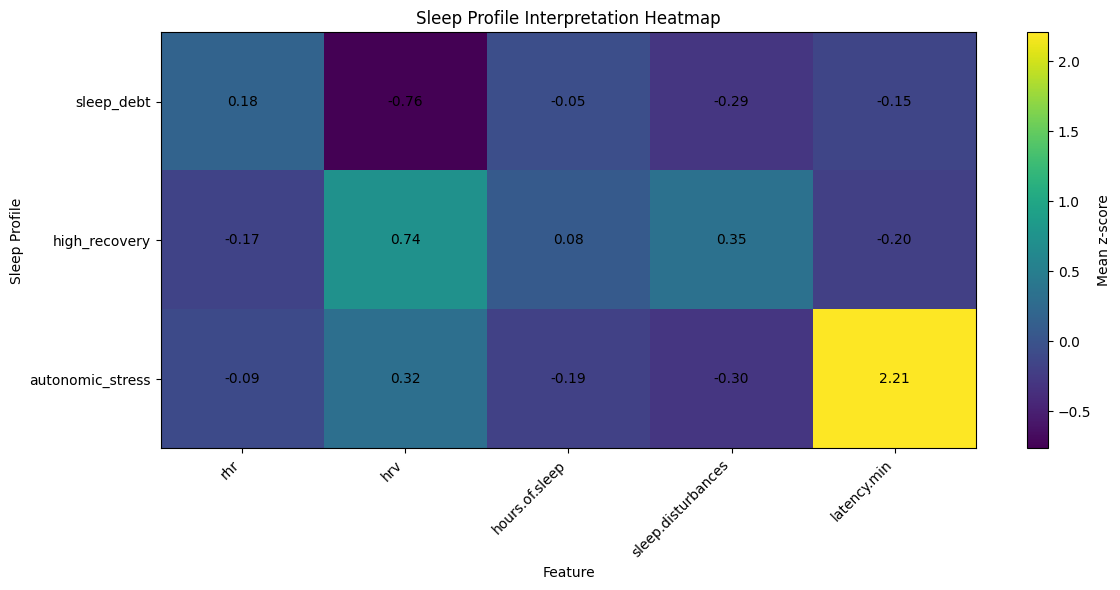

In [35]:
import pandas as pd
import matplotlib.pyplot as plt

# standardized data
scaled_df = pd.DataFrame(X_scaled, columns=features)
scaled_df["sleep_profile"] = df["sleep_profile"].values

# mean z-score for each profile
profile_z = scaled_df.groupby("sleep_profile")[features].mean()

# optional: use readable names if you already created them
if "profile_name" in df.columns:
    profile_name_map = (
        df[["sleep_profile", "profile_name"]]
        .drop_duplicates()
        .set_index("sleep_profile")["profile_name"]
        .to_dict()
    )
    profile_z = profile_z.rename(index=profile_name_map)

# plot heatmap
plt.figure(figsize=(12, 6))
plt.imshow(profile_z, aspect="auto")

plt.colorbar(label="Mean z-score")
plt.xticks(range(len(profile_z.columns)), profile_z.columns, rotation=45, ha="right")
plt.yticks(range(len(profile_z.index)), profile_z.index)

plt.title("Sleep Profile Interpretation Heatmap")
plt.xlabel("Feature")
plt.ylabel("Sleep Profile")

# add values inside cells
for i in range(profile_z.shape[0]):
    for j in range(profile_z.shape[1]):
        plt.text(j, i, f"{profile_z.iloc[i, j]:.2f}", ha="center", va="center")

plt.tight_layout()
plt.show()

In [36]:
results_df

,k,bic,aic
0,1,77636.389946,77503.654898
1,2,66736.093291,66463.986441
2,3,64796.319355,64384.840704
3,4,61599.556002,61048.705550
4,5,51595.053302,50904.831050
5,6,51441.981819,50612.387766
6,7,46097.658150,45128.692296
7,8,46059.224868,44950.887213
8,9,45975.596012,44727.886555


<Axes: xlabel='k'>

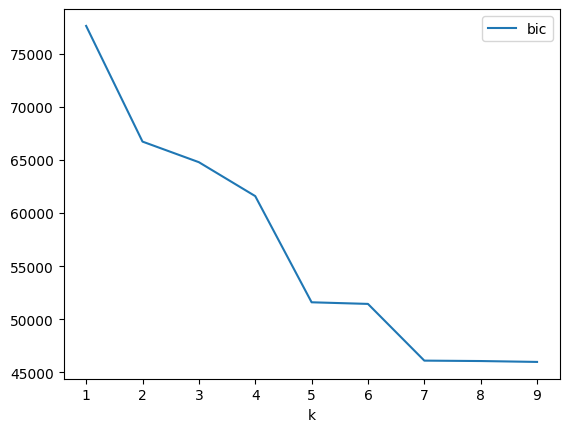

In [37]:
results_df.plot(x='k',y='bic')

In [39]:
df

,participant_id,age_group,group,date,day.of.week,rhr,hrv,sleep.onset,wake.onset,hours.in.bed,...,deep.sleep.hours,light.sleep.hours,awake.hours,missing.data.hours,session,sleep_profile,profile_0_prob,profile_1_prob,profile_2_prob,profile_name
0,sub-5006,Young,Increase,5/5/2018,Saturday,57.0,131.0,1:30:28,9:30:27,8.00,...,0.49,4.78,0.55,0.0,Pre,1,6.741183e-11,0.936678,0.063322,high_recovery
1,sub-5006,Young,Increase,5/6/2018,Sunday,63.0,51.0,2:03:05,9:25:04,7.37,...,0.52,3.67,0.85,0.0,Pre,1,4.328602e-01,0.471027,0.096112,high_recovery
2,sub-5006,Young,Increase,5/7/2018,Monday,56.0,92.0,3:53:19,9:50:47,5.96,...,0.68,2.97,0.94,0.0,Pre,1,5.827648e-04,0.966813,0.032604,high_recovery
3,sub-5006,Young,Increase,5/8/2018,Tuesday,63.0,68.0,1:56:27,7:19:26,5.38,...,0.85,2.75,0.64,0.0,Pre,1,1.768040e-01,0.798897,0.024299,high_recovery
4,sub-5006,Young,Increase,5/9/2018,Wednesday,60.0,65.0,2:52:55,9:59:54,7.12,...,0.41,4.71,1.03,0.0,Pre,0,5.643406e-01,0.420658,0.015002,sleep_debt
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
5630,sub-8034,Old,Decrease,3/13/2020,Friday,58.0,44.0,0:24:58,7:45:29,7.34,...,1.86,2.93,1.64,0.0,NaN,0,8.995359e-01,0.097389,0.003075,sleep_debt
5631,sub-8034,Old,Decrease,3/14/2020,Saturday,61.0,56.0,2:14:22,8:32:29,6.30,...,1.16,2.67,0.94,0.0,NaN,0,8.094298e-01,0.185097,0.005473,sleep_debt
5632,sub-8035,Old,Decrease,2/11/2020,Tuesday,50.0,67.0,0:29:00,7:37:58,7.15,...,1.02,4.59,0.22,0.0,NaN,0,7.344749e-01,0.257379,0.008146,sleep_debt
5633,sub-8035,Old,Decrease,2/12/2020,Wednesday,48.0,63.0,23:58:25,7:32:23,7.57,...,1.55,4.28,0.87,0.0,NaN,0,8.321533e-01,0.162051,0.005795,sleep_debt


In [40]:
import numpy as np
import plotly.graph_objects as go

from scipy.stats import multivariate_normal
from sklearn.decomposition import PCA

def plot_gmm_gaussians_pca(X, gmm, grid_size=150):

    # Reduce data to 2D
    pca = PCA(n_components=2)

    X_pca = pca.fit_transform(X)

    # Transform GMM means into PCA space
    means_pca = pca.transform(gmm.means_)

    labels = gmm.predict(X)

    x_min, x_max = X_pca[:, 0].min() - 1, X_pca[:, 0].max() + 1
    y_min, y_max = X_pca[:, 1].min() - 1, X_pca[:, 1].max() + 1

    x_grid = np.linspace(x_min, x_max, grid_size)
    y_grid = np.linspace(y_min, y_max, grid_size)

    xx, yy = np.meshgrid(x_grid, y_grid)

    fig = go.Figure()

    # Plot data points
    fig.add_trace(
        go.Scatter(
            x=X_pca[:, 0],
            y=X_pca[:, 1],
            mode="markers",
            marker=dict(
                color=labels,
                colorscale="Viridis",
                size=6,
                opacity=0.65,
                line=dict(width=0.5, color="white")
            ),
            name="Data"
        )
    )

    # Approximate covariance matrices in PCA space
    for k in range(gmm.n_components):

        cov = gmm.covariances_[k]

        # Project covariance into PCA space
        cov_pca = pca.components_ @ cov @ pca.components_.T

        rv = multivariate_normal(
            mean=means_pca[k],
            cov=cov_pca,
            allow_singular=True
        )

        grid_points = np.column_stack([
            xx.ravel(),
            yy.ravel()
        ])

        z = rv.pdf(grid_points).reshape(xx.shape)

        fig.add_trace(
            go.Contour(
                x=x_grid,
                y=y_grid,
                z=z,
                contours=dict(
                    coloring="none",
                    showlabels=False
                ),
                line=dict(width=2),
                showscale=False,
                name=f"Gaussian {k+1}"
            )
        )

        # Plot component center
        fig.add_trace(
            go.Scatter(
                x=[means_pca[k, 0]],
                y=[means_pca[k, 1]],
                mode="markers+text",
                marker=dict(
                    size=14,
                    symbol="x",
                    color="black"
                ),
                text=[f"Cluster {k+1}"],
                textposition="top center",
                name=f"Mean {k+1}"
            )
        )

    fig.update_layout(
        title="GMM Gaussian Components in PCA Space",
        xaxis_title="Principal Component 1",
        yaxis_title="Principal Component 2",
        template="plotly_white",
        width=900,
        height=750
    )

    return fig

fig = plot_gmm_gaussians_pca(
    X_scaled,
    final_gmm
)

fig.show()